# Supplementary Fig S10 · The block distance follows the whole-matrix distance, every dataset

Fig S9 per dataset instead of per niche. Every dataset, seed-0 layout: 1,000 random pairs of index tiles drawn
uniformly from all pairs of tiles in the same niche (d_B exists only within a niche, where both tiles share its gene
order and blocks), so the niches contribute in proportion to their pairs.

* **A–D, I–L** one dataset each: the block distance d_B against the whole-matrix log-Euclidean distance d_W of each
  pair; dashed y = x; Spearman and Pearson correlation.
* **E–H, M–P** below each, on the same x axis: the gap d_W − d_B of each pair; dashed zero, solid the median gap.

**Run first:** `R12_block_distance` (`results/block_distance/dataset_pairs.csv`, `datasets.csv`).
Writes `figures/figS10_block_distance_datasets/`.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datasets.yaml").exists())
sys.path.insert(0, str(ROOT / "experiments" / "common"))
import numpy as np
import pandas as pd
from matplotlib.ticker import MaxNLocator
from scipy.stats import pearsonr, spearmanr

import style as ps

FIG = "figS10_block_distance_datasets"
RES = ROOT / "results" / "block_distance"
PW, PH, DH = 45.0, 47.0, 35.0   # mm: column; scatter panel (square 32 mm axes); gap panel below
L, R = 11.0, 2.0                # mm: axes margins inside a column (as Fig S9)
DASH, DLW = (0, (3, 2)), 0.6     # y = x and zero lines: dash pattern, width (pt)
KEYS = ps.DATASET_ORDER

pairs = pd.read_csv(RES / "dataset_pairs.csv")
info = pd.read_csv(RES / "datasets.csv").set_index("key")
print(sorted(set(pairs.tag)), info[["tiles", "niches", "niches_sampled", "p"]].to_dict("index"))

['method-v2'] {'skin_melanoma': {'tiles': 839, 'niches': 4, 'niches_sampled': 4, 'p': 382}, 'kidney_nondiseased': {'tiles': 705, 'niches': 2, 'niches_sampled': 2, 'p': 377}, 'breast_cancer': {'tiles': 1840, 'niches': 4, 'niches_sampled': 4, 'p': 313}, 'lung_cancer': {'tiles': 1535, 'niches': 3, 'niches_sampled': 3, 'p': 377}, 'pancreatic_cancer': {'tiles': 2061, 'niches': 4, 'niches_sampled': 4, 'p': 474}, 'lymph_node': {'tiles': 2354, 'niches': 5, 'niches_sampled': 5, 'p': 377}, 'lymph_node_5k': {'tiles': 6972, 'niches': 15, 'niches_sampled': 15, 'p': 400}, 'brain_cancer': {'tiles': 9558, 'niches': 18, 'niches_sampled': 18, 'p': 480}}


## Per dataset (shown, not saved)

In [2]:
def summary(g):
    gap = g.d_whole - g.d_block
    return pd.Series({"pairs": len(g), "niches_sampled": g.niche.nunique(),
                      "pearson_r": pearsonr(g.d_whole, g.d_block)[0],
                      "spearman_rho": spearmanr(g.d_whole, g.d_block)[0],
                      "median_gap": float(np.median(gap)),
                      "median_ratio_block_whole": float(np.median(g.d_block / g.d_whole)),
                      "frac_block_le_whole": float(np.mean(gap >= 0))})

pairs.groupby("key").apply(summary).loc[KEYS].rename(index=ps.DATASET_LABELS).round(3)

,pairs,niches_sampled,pearson_r,spearman_rho,median_gap,median_ratio_block_whole,frac_block_le_whole
key,,,,,,,
Skin,1000.0,4.0,0.951,0.899,0.372,0.745,1.000
Kidney,1000.0,2.0,0.982,0.982,0.167,0.836,1.000
Breast,1000.0,4.0,0.974,0.935,0.255,0.797,0.994
Lung,1000.0,3.0,0.953,0.912,0.306,0.770,0.995
Pancreas,1000.0,4.0,0.926,0.890,0.420,0.664,1.000
Lymph node,1000.0,5.0,0.898,0.882,0.372,0.699,0.999
Lymph node 5k,1000.0,15.0,0.509,0.192,0.874,0.519,1.000
Brain,1000.0,18.0,0.882,0.795,0.333,0.674,1.000


## Scatter (d_B against d_W) and gap (d_W − d_B) panels

figures/figS10_block_distance_datasets/panels/A.pdf/.png: 45 x 47 mm, 0.0 / 0.3 MB
figures/figS10_block_distance_datasets/panels/E.pdf/.png: 45 x 35 mm, 0.0 / 0.3 MB
figures/figS10_block_distance_datasets/panels/B.pdf/.png: 45 x 47 mm, 0.0 / 0.3 MB
figures/figS10_block_distance_datasets/panels/F.pdf/.png: 45 x 35 mm, 0.0 / 0.3 MB
figures/figS10_block_distance_datasets/panels/C.pdf/.png: 45 x 47 mm, 0.0 / 0.3 MB
figures/figS10_block_distance_datasets/panels/G.pdf/.png: 45 x 35 mm, 0.0 / 0.3 MB
figures/figS10_block_distance_datasets/panels/D.pdf/.png: 45 x 47 mm, 0.0 / 0.3 MB
figures/figS10_block_distance_datasets/panels/H.pdf/.png: 45 x 35 mm, 0.0 / 0.2 MB
figures/figS10_block_distance_datasets/panels/I.pdf/.png: 45 x 47 mm, 0.0 / 0.3 MB
figures/figS10_block_distance_datasets/panels/M.pdf/.png: 45 x 35 mm, 0.0 / 0.3 MB
figures/figS10_block_distance_datasets/panels/J.pdf/.png: 45 x 47 mm, 0.0 / 0.4 MB
figures/figS10_block_distance_datasets/panels/N.pdf/.png: 45 x 35 mm, 0.0 / 0.3 MB
figu

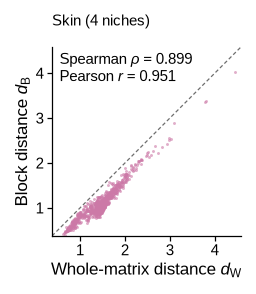

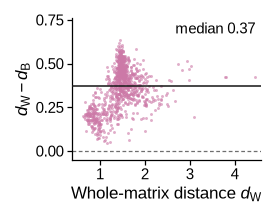

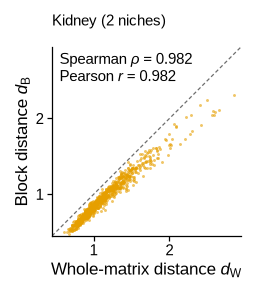

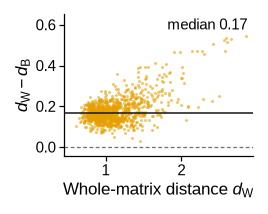

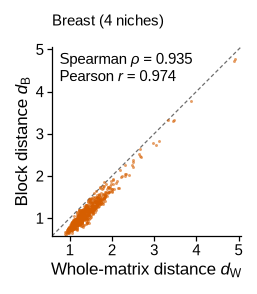

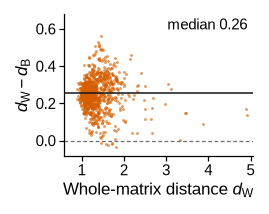

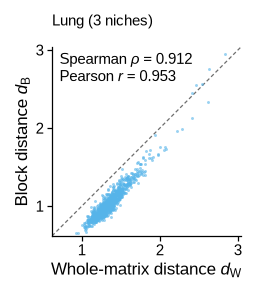

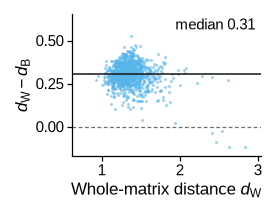

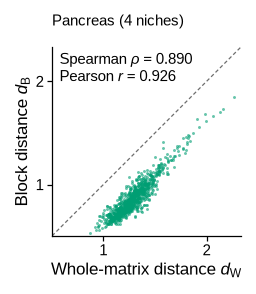

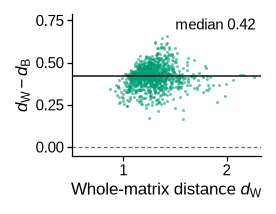

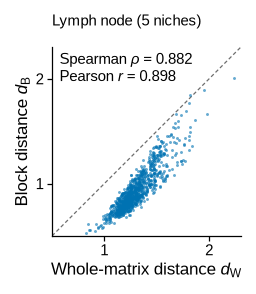

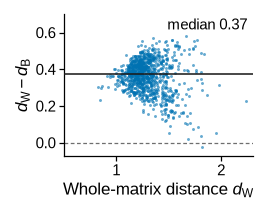

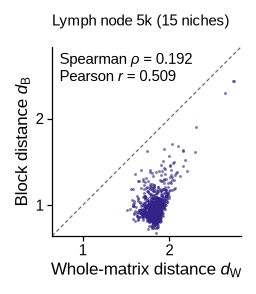

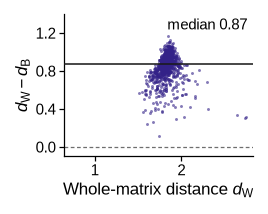

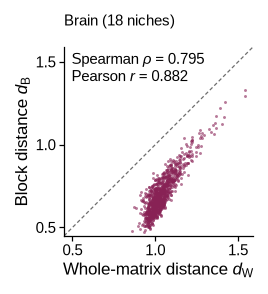

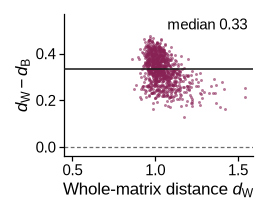

In [3]:
def limits(g):
    return 0.95 * min(g.d_whole.min(), g.d_block.min()), 1.03 * max(g.d_whole.max(), g.d_block.max())


def ticks(axis):
    axis.set_major_locator(MaxNLocator(nbins=5, integer=True, steps=[1, 2, 5, 10]))


def panel_scatter(fig, key):
    g = pairs[pairs.key == key]
    ax = ps.axes(fig, left=L, bottom=9, right=R, top=6)
    lo, hi = limits(g)
    ax.plot([lo, hi], [lo, hi], color=ps.MUTED, lw=DLW, ls=DASH, zorder=1)
    ax.scatter(g.d_whole, g.d_block, s=2, lw=0, alpha=0.6, color=ps.DATASET_COLORS[key], zorder=2)
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect("equal")
    ticks(ax.xaxis); ticks(ax.yaxis)
    ax.set_xlabel("Whole-matrix distance $d_{\\mathrm{W}}$")
    ax.set_ylabel("Block distance $d_{\\mathcal{B}}$")
    rho, r = spearmanr(g.d_whole, g.d_block)[0], pearsonr(g.d_whole, g.d_block)[0]
    ax.text(0.04, 0.97, f"Spearman $\\rho$ = {rho:.3f}\nPearson $r$ = {r:.3f}",
            transform=ax.transAxes, va="top", ha="left", fontsize=ps.TICK_PT)
    W_, H_ = ps.size_mm(fig)
    fig.text(L / W_, 1 - 0.5 / H_, f"{ps.DATASET_LABELS[key]} ({info.loc[key, 'niches']} niches)",
             ha="left", va="top", fontsize=ps.TICK_PT)


def panel_gap(fig, key):
    g = pairs[pairs.key == key]
    gap = g.d_whole - g.d_block
    ax = ps.axes(fig, left=L, bottom=9, right=R, top=2)
    lo, hi = limits(g)
    ax.axhline(0, color=ps.MUTED, lw=DLW, ls=DASH, zorder=1)
    ax.scatter(g.d_whole, gap, s=2, lw=0, alpha=0.6, color=ps.DATASET_COLORS[key], zorder=2)
    m = float(np.median(gap))
    ax.axhline(m, color=ps.INK, lw=ps.LW, zorder=3)
    span = gap.max() - min(0.0, gap.min())
    ax.set_xlim(lo, hi); ax.set_ylim(min(0.0, gap.min()) - 0.08 * span, gap.max() + 0.2 * span)  # room for the label
    ticks(ax.xaxis)
    ax.yaxis.set_major_locator(MaxNLocator(nbins=4))
    ax.set_xlabel("Whole-matrix distance $d_{\\mathrm{W}}$")
    ax.set_ylabel("$d_{\\mathrm{W}} - d_{\\mathcal{B}}$")
    ax.text(0.97, 0.97, f"median {m:.2f}", transform=ax.transAxes, va="top", ha="right", fontsize=ps.TICK_PT)


LETTERS = "ABCDEFGHIJKLMNOP"
for i, key in enumerate(KEYS):
    blk, col = divmod(i, 4)
    fig = ps.panel(PW, PH); panel_scatter(fig, key); ps.save_panel(fig, FIG, LETTERS[blk * 8 + col])
    fig = ps.panel(PW, DH); panel_gap(fig, key); ps.save_panel(fig, FIG, LETTERS[blk * 8 + 4 + col])

## Full figure

figures/figS10_block_distance_datasets/figS10_block_distance_datasets.pdf/.png: 180 x 164 mm, 0.3 / 4.8 MB


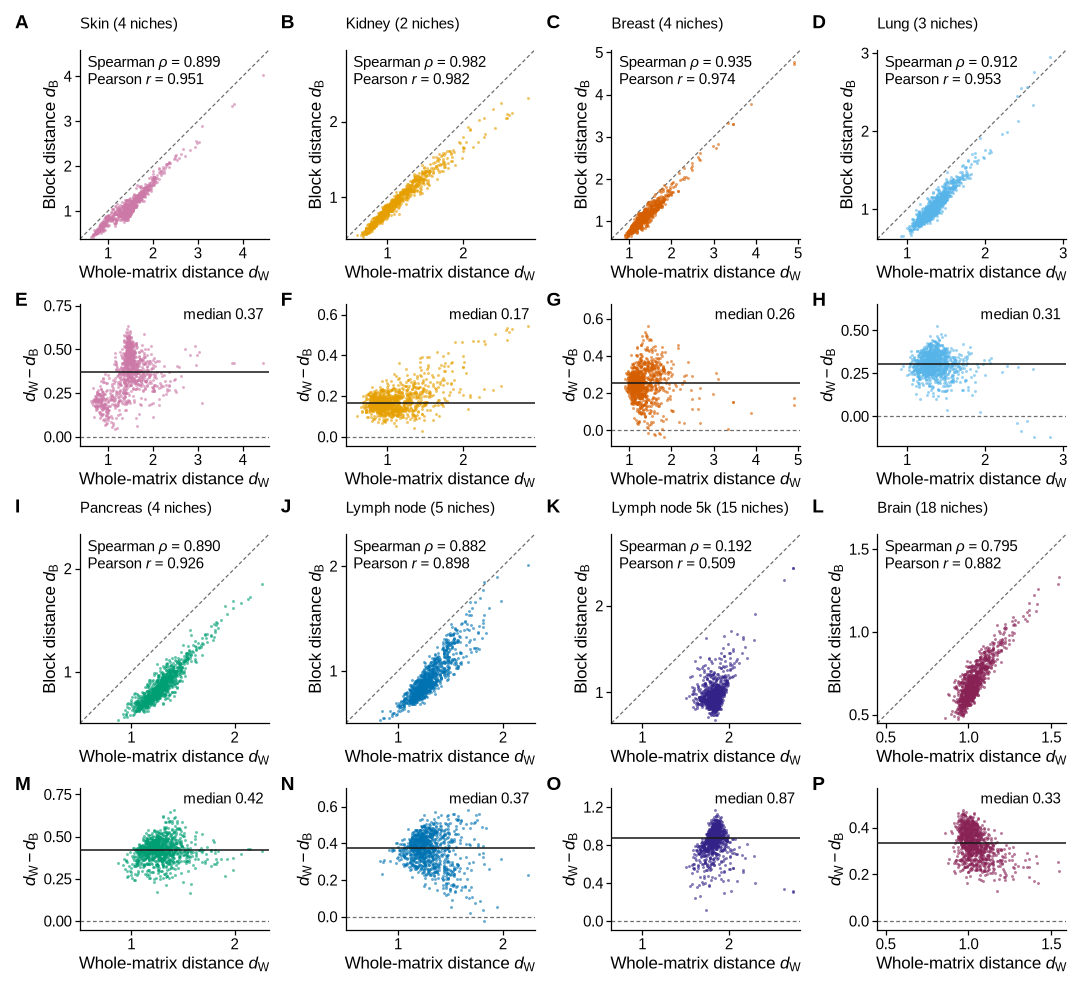

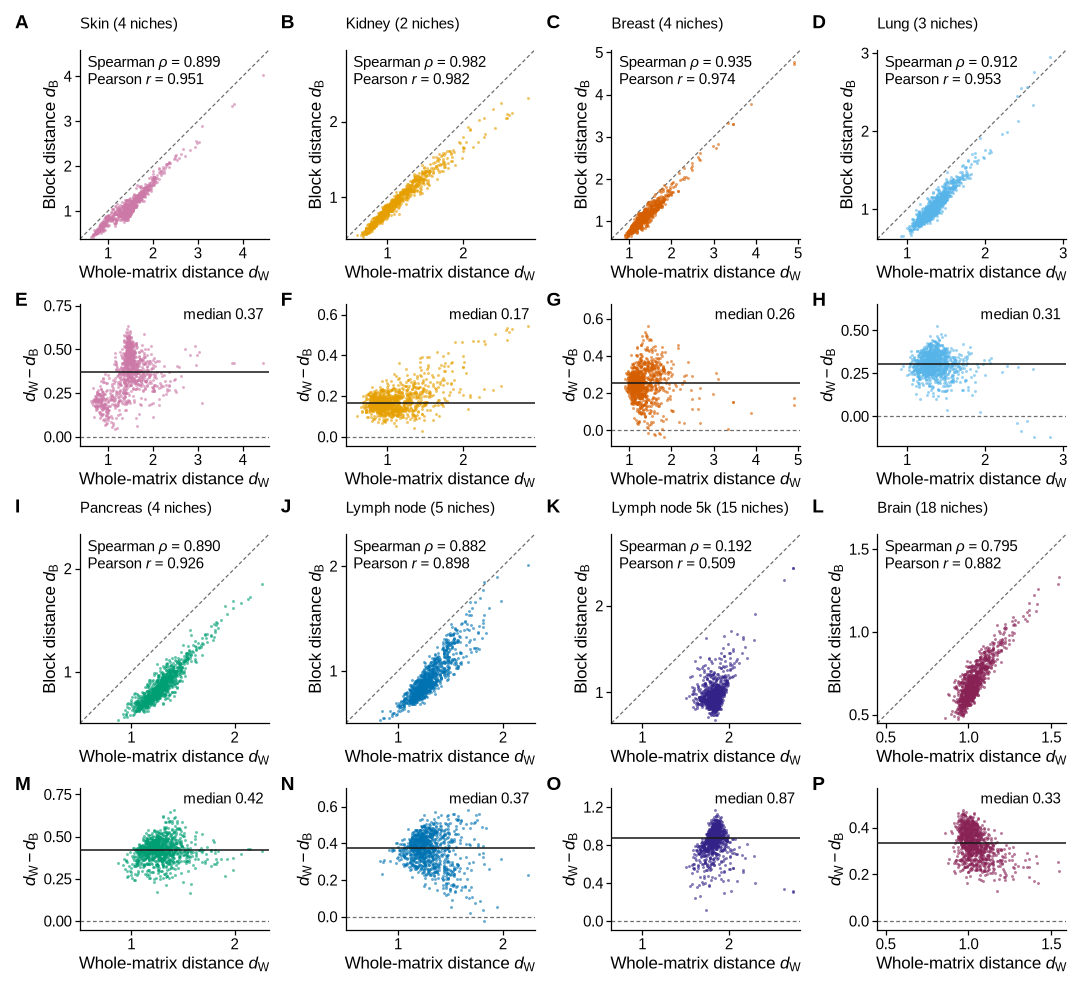

In [4]:
page = ps.page(4 * PW, 2 * (PH + DH))
for i, key in enumerate(KEYS):
    blk, col = divmod(i, 4)
    y0 = blk * (PH + DH)
    panel_scatter(ps.place(page, LETTERS[blk * 8 + col], x=col * PW, y=y0, w=PW, h=PH), key)
    panel_gap(ps.place(page, LETTERS[blk * 8 + 4 + col], x=col * PW, y=y0 + PH, w=PW, h=DH), key)
ps.save_figure(page, FIG)
page